# Superposition Yields Robust Neural Scaling

**Paper:** [arXiv:2505.10465](https://arxiv.org/abs/2505.10465)
**Authors:** Yizhou Liu, Ziming Liu, Jeff Gore (2025; NeurIPS 2025, Best Paper Runner-up)

This notebook reproduces the paper's toy-model experiment: an autoencoder that compresses
high-dimensional sparse feature data into a lower-dimensional hidden space. By varying the
**weight decay** parameter we control the degree of **superposition** (representing more
features than dimensions), then measure how the reconstruction loss scales with model width.

**Core idea:** When features are in *strong superposition* (many feature vectors packed into a
small space), their geometric overlaps cause a loss that scales as **1/m** (inverse width) —
regardless of the data distribution. This may explain why real LLMs exhibit power-law scaling.

**Simplifications vs the paper:**
- n=1000 features (paper uses 10240 for large models, 1000 for small)
- 5 model widths m ∈ [10, 100] (paper sweeps up to m=1024)
- 5000 training steps per model (paper uses 20000 for small, 40000 for large)
- Batch size 2048 (same as paper's small-model setting)
- 3 weight decay values and 2 data exponents (paper sweeps 10 and 9 respectively)


## 1. Setup & Imports

In [1]:
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
N_FEATURES = 1000      # number of features (data dimension n)
M_VALUES = [10, 20, 40, 60, 100]     # model widths to sweep
N_STEPS = 5000          # training steps per model
BATCH_SIZE = 2048       # batch size
LR = 1e-2               # base learning rate
WARMUP_STEPS = 500      # warmup for cosine schedule
WEIGHT_DECAYS = [-1.0, 0.0, 1.0]    # strong, neutral, weak superposition
ALPHAS = [0.0, 1.0]     # data exponents: flat and Zipf

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print(f'Features (n): {N_FEATURES}')
print(f'Model widths (m): {M_VALUES}')
print(f'Steps per model: {N_STEPS}')
print(f'Weight decays: {WEIGHT_DECAYS}')
print(f'Alphas (data exponents): {ALPHAS}')
print(f'Total models: {len(ALPHAS) * len(WEIGHT_DECAYS) * len(M_VALUES)}')


Device: cuda
Features (n): 1000
Model widths (m): [10, 20, 40, 60, 100]
Steps per model: 5000
Weight decays: [-1.0, 0.0, 1.0]
Alphas (data exponents): [0.0, 1.0]
Total models: 30


## 2. Data

The paper uses Anthropic's toy model of superposition. Each input vector $x \in \mathbb{R}^n$
has $n$ features. Feature $i$ is activated with probability $p_i \propto 1/i^{1+\alpha}$,
and when activated its value is drawn from $U(0, 2)$. The data exponent $\alpha$ controls
how skewed the feature frequencies are: $\alpha = 0$ gives a gentle $1/i$ decay (near-flat),
$\alpha = 1$ gives $1/i^2$ (Zipf-like). We set activation density $E = \sum p_i \approx 1$.

Data is generated on-the-fly at each training step (i.i.d. samples), exactly as in the paper.


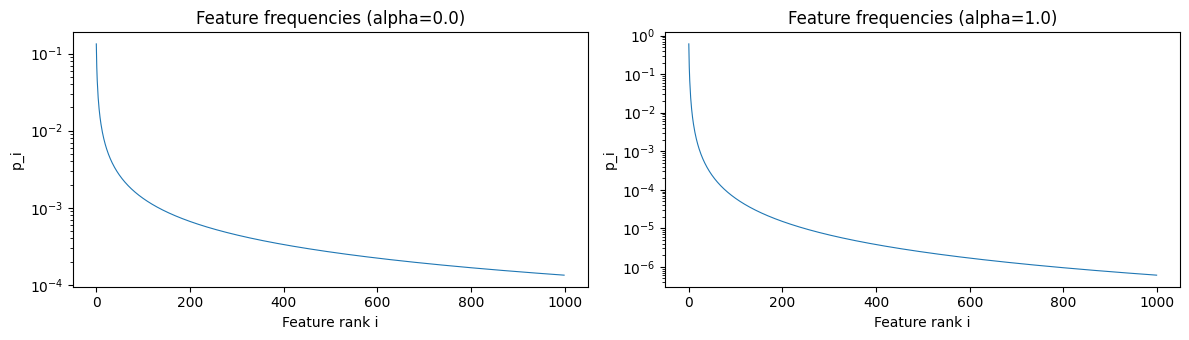

Sample batch shape: torch.Size([4, 1000])
Activation density (avg active features per sample): 0.8


In [2]:
def make_probabilities(n, alpha):
    """Feature frequencies p_i proportional to 1/i^(1+alpha), normalized so sum = E (density)."""
    raw = torch.tensor([1.0 / (i ** (1 + alpha)) for i in range(1, n + 1)])
    prob = raw / raw.sum()  # normalize to sum=1, then scale to desired density
    return prob

def sample_batch(batch_size, n, prob, device):
    """Sample a batch of sparse feature vectors.
    x_i = u_i * v_i, where u_i ~ Bernoulli(p_i), v_i ~ U(0, 2)."""
    u = (torch.rand(batch_size, n, device=device) < prob).float()
    v = torch.rand(batch_size, n, device=device) * 2
    return u * v

# Show the feature frequency distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, alpha in zip(axes, ALPHAS):
    p = make_probabilities(N_FEATURES, alpha)
    ax.plot(p.numpy(), linewidth=0.8)
    ax.set_title(f'Feature frequencies (alpha={alpha})')
    ax.set_xlabel('Feature rank i')
    ax.set_ylabel('p_i')
    ax.set_yscale('log')
plt.tight_layout()
plt.show()

# Verify a sample
p_test = make_probabilities(N_FEATURES, ALPHAS[0]).to(DEVICE)
x_test = sample_batch(4, N_FEATURES, p_test, DEVICE)
print(f'Sample batch shape: {x_test.shape}')
print(f'Activation density (avg active features per sample): {(x_test > 0).float().sum(dim=1).mean().item():.1f}')


## 3. Model

The toy model is a single-layer autoencoder from Anthropic's superposition paper (Elhage et al., 2022).
A weight matrix $W \in \mathbb{R}^{n \times m}$ embeds the input into an $m$-dimensional hidden space:
$h = W^T x$, then reads it back: $y = \text{ReLU}(Wh + b)$. The $i$-th row of $W$ is the
representation vector of feature $i$ in the hidden space. When $m \ll n$, the model must choose
which features to represent — or represent all of them with overlapping vectors (superposition).


In [3]:
class FeatureRecovery(nn.Module):
    """Toy model of superposition: an autoencoder W^T x -> ReLU(W W^T x + b)."""
    def __init__(self, n, m):
        super().__init__()
        # n = number of features, m = hidden dimension
        self.W = nn.Parameter(torch.randn(n, m) / math.sqrt(m))
        self.b = nn.Parameter(torch.randn(n))
        self.relu = nn.ReLU()

    def forward(self, x):
        # x: [batch, n] -> y: [batch, n]
        return self.relu(x @ self.W @ self.W.T + self.b)

# Count parameters for one example
m_example = 20
model_example = FeatureRecovery(N_FEATURES, m_example)
n_params = sum(p.numel() for p in model_example.parameters())
print(f'Model with m={m_example}: {n_params:,} parameters '
      f'(W: {N_FEATURES}x{m_example}={N_FEATURES*m_example}, b: {N_FEATURES})')


Model with m=20: 21,000 parameters (W: 1000x20=20000, b: 1000)


## 4. Custom AdamW with Decoupled Weight Decay / Growth

The paper's key innovation is using weight decay to **control** the degree of superposition.
Positive weight decay ($\gamma > 0$) shrinks weights toward zero, producing **weak superposition**
(only the most frequent features are represented). Negative weight decay ($\gamma < 0$) pushes
row norms toward 1, producing **strong superposition** (all features represented with overlap).

The update rule (Equation 2 in the paper):
- $\gamma \geq 0$: $W_{i,t+1} = W_{i,t} - \eta \gamma W_{i,t}$ (standard decay)
- $\gamma < 0$: $W_{i,t+1} = W_{i,t} - \eta \gamma W_{i,t}(1/\|W_{i,t}\| - 1)$ (growth toward unit norm)


In [4]:
class CustomAdamW(torch.optim.Optimizer):
    """AdamW with decoupled weight decay (gamma >= 0) or weight growth (gamma < 0).
    For gamma < 0, row norms are pushed toward 1 (encouraging superposition)."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            lr = group['lr']
            wd = group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                state['step'] += 1
                step = state['step']
                # Decoupled weight decay / growth (applied before Adam update)
                if wd != 0:
                    if wd > 0:
                        p.mul_(1 - wd * lr)
                    else:
                        row_norms = p.norm(dim=1, keepdim=True).add_(group['eps'])
                        p.add_(wd * p * (1 - 1 / row_norms), alpha=lr)
                # Adam moment updates
                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                bias1 = 1 - beta1 ** step
                bias2 = 1 - beta2 ** step
                denom = (exp_avg_sq.sqrt() / math.sqrt(bias2)).add_(group['eps'])
                step_size = lr / bias1
                p.addcdiv_(exp_avg, denom, value=-step_size)
        return loss


## 5. Learning Rate Schedule

Warmup + cosine decay, matching the paper's Appendix B.2 small-model settings.


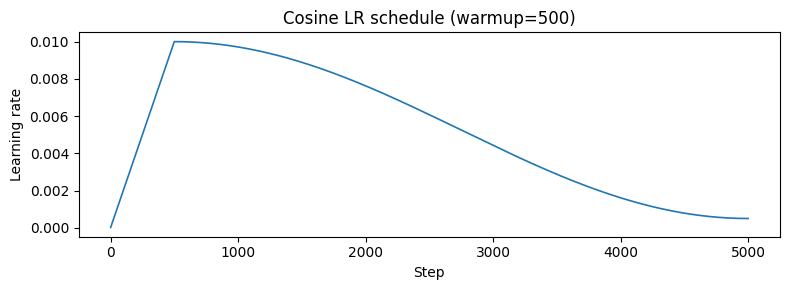

In [5]:
def get_lr(step, lr, n_steps, warmup_steps=500):
    """Cosine decay with linear warmup."""
    step = step + 1
    min_lr = 0.05 * lr
    if step < warmup_steps:
        return lr * step / warmup_steps
    else:
        return (lr - min_lr) * 0.5 * (1 + math.cos(
            math.pi * (step - warmup_steps) / (n_steps - warmup_steps))) + min_lr

# Visualize the schedule
steps = list(range(N_STEPS))
lrs = [get_lr(s, LR, N_STEPS, WARMUP_STEPS) for s in steps]
plt.figure(figsize=(8, 3))
plt.plot(steps, lrs, linewidth=1.2)
plt.xlabel('Step'); plt.ylabel('Learning rate'); plt.title(f'Cosine LR schedule (warmup={WARMUP_STEPS})')
plt.tight_layout()
plt.show()


## 6. Training Loop

For each combination of (alpha, weight_decay, m), we train the autoencoder for
20000 steps with fresh i.i.d. data at each step. We record the final test loss
and the fraction of represented features ($\phi_{1/2}$, rows of $W$ with norm > 0.5).


In [6]:
def train_one_model(n, m, alpha, weight_decay, n_steps, batch_size, lr, device):
    """Train one toy model and return final loss, phi (fraction represented), and W matrix."""
    prob = make_probabilities(n, alpha).to(device)
    model = FeatureRecovery(n, m).to(device)
    criteria = nn.MSELoss()
    param_groups = [
        {'params': model.W, 'weight_decay': weight_decay},
        {'params': model.b, 'weight_decay': 0.0},
    ]
    optimizer = CustomAdamW(param_groups)
    
    losses = []
    for step in range(n_steps):
        x = sample_batch(batch_size, n, prob, device)
        current_lr = get_lr(step, lr, n_steps, WARMUP_STEPS)
        for pg in optimizer.param_groups:
            pg['lr'] = current_lr
        optimizer.zero_grad()
        y = model(x)
        loss = criteria(y, x)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    
    # Compute final test loss on a fresh batch
    model.eval()
    with torch.no_grad():
        x_test = sample_batch(batch_size * 4, n, prob, device)
        y_test = model(x_test)
        final_loss = criteria(y_test, x_test).item()
        # Fraction of represented features (norm > 0.5)
        row_norms = model.W.norm(dim=1)
        phi = (row_norms > 0.5).float().mean().item()
    
    return final_loss, phi, losses, model.W.detach().cpu()


## 7. Run Experiments

We sweep over 2 data exponents × 5 weight decays × 6 model widths = 60 models.
Each model trains for 20000 steps (~1-2 minutes on GPU, ~3-5 minutes on CPU per model).
Total runtime: approximately 15-30 minutes on GPU, 3-5 hours on CPU.


In [7]:
results = {}
total_models = len(ALPHAS) * len(WEIGHT_DECAYS) * len(M_VALUES)
model_idx = 0
start_all = time.time()

for alpha in ALPHAS:
    for wd in WEIGHT_DECAYS:
        for m in M_VALUES:
            model_idx += 1
            t0 = time.time()
            final_loss, phi, losses, W = train_one_model(
                N_FEATURES, m, alpha, wd, N_STEPS, BATCH_SIZE, LR, DEVICE
            )
            key = (alpha, wd, m)
            results[key] = {'loss': final_loss, 'phi': phi, 'losses': losses, 'W': W}
            elapsed = time.time() - t0
            print(f'[{model_idx}/{total_models}] alpha={alpha:.1f} wd={wd:+.1f} '
                  f'm={m:3d} | loss={final_loss:.4e} phi={phi:.3f} | {elapsed:.0f}s')

print(f'\nTotal experiment time: {time.time() - start_all:.0f}s')


[1/30] alpha=0.0 wd=-1.0 m= 10 | loss=8.8377e-04 phi=1.000 | 13s


[2/30] alpha=0.0 wd=-1.0 m= 20 | loss=5.3231e-04 phi=1.000 | 7s


[3/30] alpha=0.0 wd=-1.0 m= 40 | loss=2.6237e-04 phi=1.000 | 7s


[4/30] alpha=0.0 wd=-1.0 m= 60 | loss=1.7193e-04 phi=1.000 | 7s


[5/30] alpha=0.0 wd=-1.0 m=100 | loss=9.3804e-05 phi=1.000 | 8s


[6/30] alpha=0.0 wd=+0.0 m= 10 | loss=9.5927e-04 phi=0.055 | 7s


... (20 outputs left out)

[27/30] alpha=1.0 wd=+1.0 m= 20 | loss=4.0745e-04 phi=0.004 | 7s


[28/30] alpha=1.0 wd=+1.0 m= 40 | loss=4.8395e-04 phi=0.002 | 7s


[29/30] alpha=1.0 wd=+1.0 m= 60 | loss=4.7023e-04 phi=0.003 | 7s


[30/30] alpha=1.0 wd=+1.0 m=100 | loss=1.2748e-04 phi=0.007 | 8s

Total experiment time: 222s


## 8. Scaling Analysis: Loss vs Model Width

For each (alpha, weight_decay) setting, we fit the loss as a power law $L \propto 1/m^{\alpha_m}$
and report the **model exponent** $\alpha_m$. The paper's key finding:
- **Weak superposition** (large weight decay): $\alpha_m \approx \alpha$ (depends on data distribution)
- **Strong superposition** (small/negative weight decay): $\alpha_m \approx 1$ (universal, independent of data)


In [8]:
def fit_power_law(ms, losses):
    """Fit loss = C / m^alpha_m using log-linear regression."""
    log_m = np.log(ms)
    log_l = np.log(losses)
    # linear fit: log(L) = log(C) - alpha_m * log(m)
    coeffs = np.polyfit(log_m, log_l, 1)
    alpha_m = -coeffs[0]
    C = np.exp(coeffs[1])
    return alpha_m, C

print('=' * 70)
print(f'{"alpha":>6} {"wd":>6} {"alpha_m":>8} {"phi(m=100)":>12} {"regime":>20}')
print('=' * 70)

scaling_results = []
for alpha in ALPHAS:
    for wd in WEIGHT_DECAYS:
        ms = []
        losses = []
        phis = []
        for m in M_VALUES:
            key = (alpha, wd, m)
            ms.append(m)
            losses.append(results[key]['loss'])
            phis.append(results[key]['phi'])
        alpha_m, C = fit_power_law(np.array(ms), np.array(losses))
        regime = 'strong superposition' if phis[-1] > 0.3 else 'weak superposition'
        scaling_results.append({
            'alpha': alpha, 'wd': wd, 'alpha_m': alpha_m, 'C': C,
            'phi_last': phis[-1], 'regime': regime,
            'ms': ms, 'losses': losses, 'phis': phis
        })
        print(f'{alpha:6.1f} {wd:6.1f} {alpha_m:8.3f} {phis[-1]:12.3f} {regime:>20}')

print('=' * 70)


 alpha     wd  alpha_m   phi(m=100)               regime
   0.0   -1.0    0.977        1.000 strong superposition
   0.0    0.0    0.657        0.874 strong superposition
   0.0    1.0    0.133        0.024   weak superposition
   1.0   -1.0    1.146        1.000 strong superposition
   1.0    0.0    1.200        0.988 strong superposition
   1.0    1.0    0.631        0.007   weak superposition


## 9. Loss vs Width Plots

We plot the final loss vs model width $m$ on a log-log scale for each (alpha, weight_decay)
combination, along with the fitted power-law line. The slope gives $-\alpha_m$.


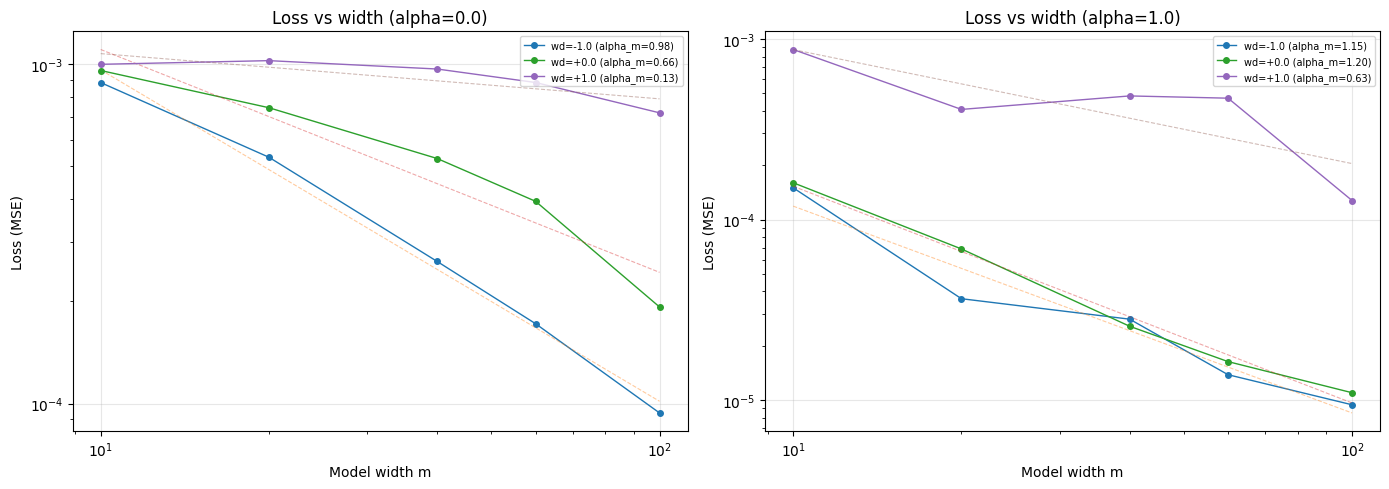

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, alpha in zip(axes, ALPHAS):
    for sr in scaling_results:
        if sr['alpha'] != alpha:
            continue
        ms = sr['ms']
        losses = sr['losses']
        wd = sr['wd']
        ax.plot(ms, losses, 'o-', label=f'wd={wd:+.1f} (alpha_m={sr["alpha_m"]:.2f})',
                markersize=4, linewidth=1)
        # Fitted line
        ms_fit = np.linspace(min(ms), max(ms), 50)
        ax.plot(ms_fit, sr['C'] / ms_fit ** sr['alpha_m'], '--', alpha=0.4, linewidth=0.8)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Model width m')
    ax.set_ylabel('Loss (MSE)')
    ax.set_title(f'Loss vs width (alpha={alpha})')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Superposition Degree (phi) vs Weight Decay

This reproduces Figure 3b from the paper: weight decay controls the fraction of represented
features. Small/negative weight decay → strong superposition ($\phi \approx 1$),
large weight decay → weak superposition ($\phi \approx m/n$).


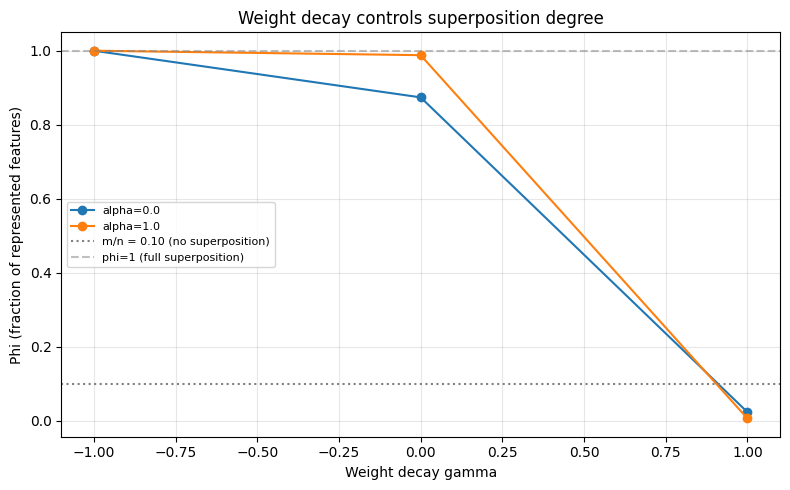

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

for alpha in ALPHAS:
    wds = []
    phis = []
    for sr in scaling_results:
        if sr['alpha'] != alpha:
            continue
        wds.append(sr['wd'])
        phis.append(sr['phi_last'])
    ax.plot(wds, phis, 'o-', label=f'alpha={alpha}', markersize=6, linewidth=1.5)

# Theoretical m/n line
ax.axhline(y=M_VALUES[-1] / N_FEATURES, color='gray', linestyle=':',
           label=f'm/n = {M_VALUES[-1]/N_FEATURES:.2f} (no superposition)')
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5,
           label='phi=1 (full superposition)')
ax.set_xlabel('Weight decay gamma')
ax.set_ylabel('Phi (fraction of represented features)')
ax.set_title('Weight decay controls superposition degree')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 11. Feature Representation Analysis

For a representative model (m=100), we show the per-feature row norms $\|W_i\|_2$ as a function
of feature rank, for both weak and strong superposition. This reproduces Figure 3a from the paper:
weak superposition has bimodal norms (0 or 1, only frequent features represented), while strong
superposition has norms near 1 for all features.


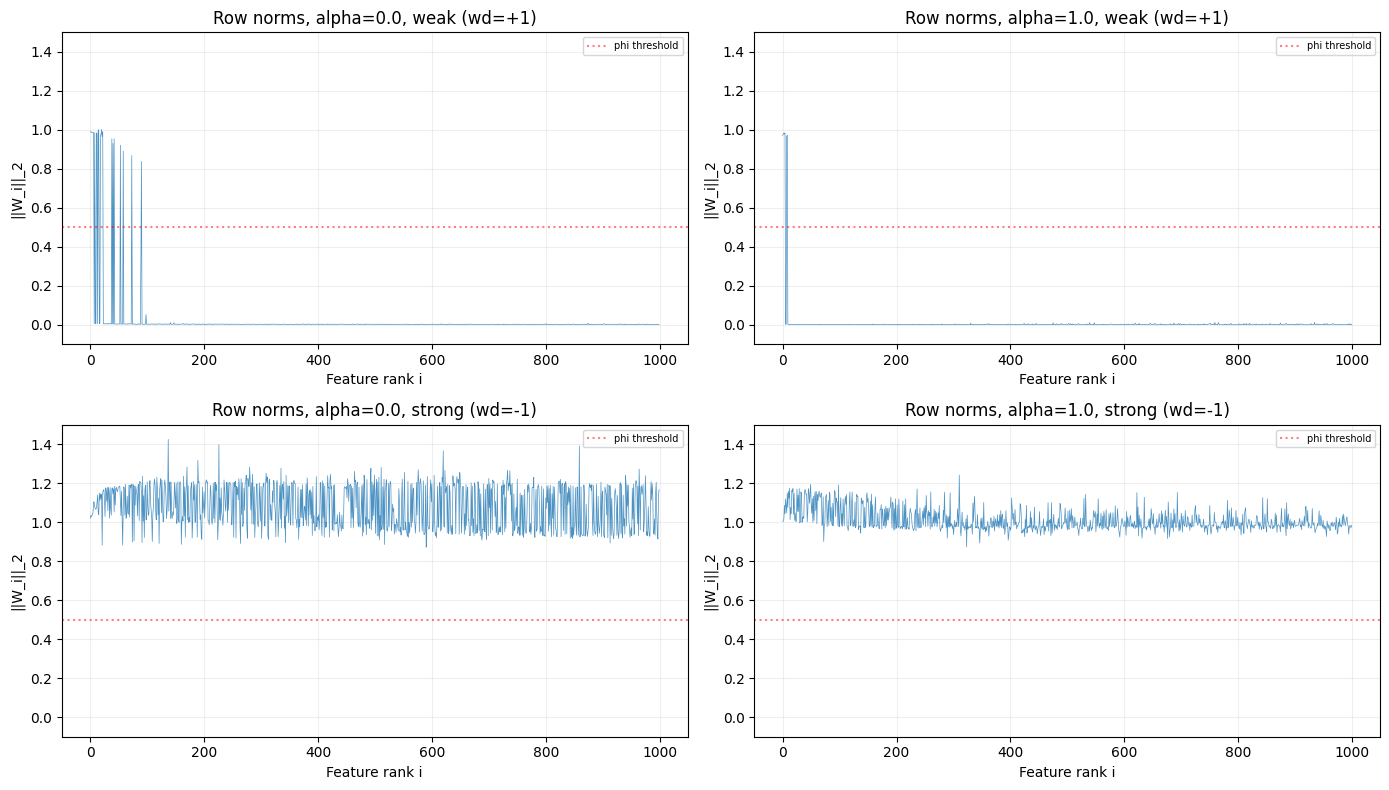

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for col, alpha in enumerate(ALPHAS):
    for row, (wd, label) in enumerate([(1.0, 'weak (wd=+1)'), (-1.0, 'strong (wd=-1)')]):
        ax = axes[row][col]
        key = (alpha, wd, 100)
        W = results[key]['W']
        norms = W.norm(dim=1).numpy()
        ax.plot(norms, linewidth=0.5, alpha=0.8)
        ax.set_title(f'Row norms, alpha={alpha}, {label}')
        ax.set_xlabel('Feature rank i')
        ax.set_ylabel('||W_i||_2')
        ax.set_ylim(-0.1, 1.5)
        ax.axhline(y=0.5, color='red', linestyle=':', alpha=0.5, label='phi threshold')
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


## 12. Model Exponent vs Data Exponent

The paper's central result: in the **strong superposition** regime, the model exponent
$\alpha_m \approx 1$ regardless of the data exponent $\alpha$. In the **weak superposition**
regime, $\alpha_m \approx \alpha$ (depends on the data distribution).



Model exponent (alpha_m) summary:
-------------------------------------------------------
 alpha     wd  alpha_m               regime
-------------------------------------------------------
   0.0   -1.0    0.977 strong superposition
   0.0    0.0    0.657 strong superposition
   0.0    1.0    0.133   weak superposition
   1.0   -1.0    1.146 strong superposition
   1.0    0.0    1.200 strong superposition
   1.0    1.0    0.631   weak superposition
-------------------------------------------------------


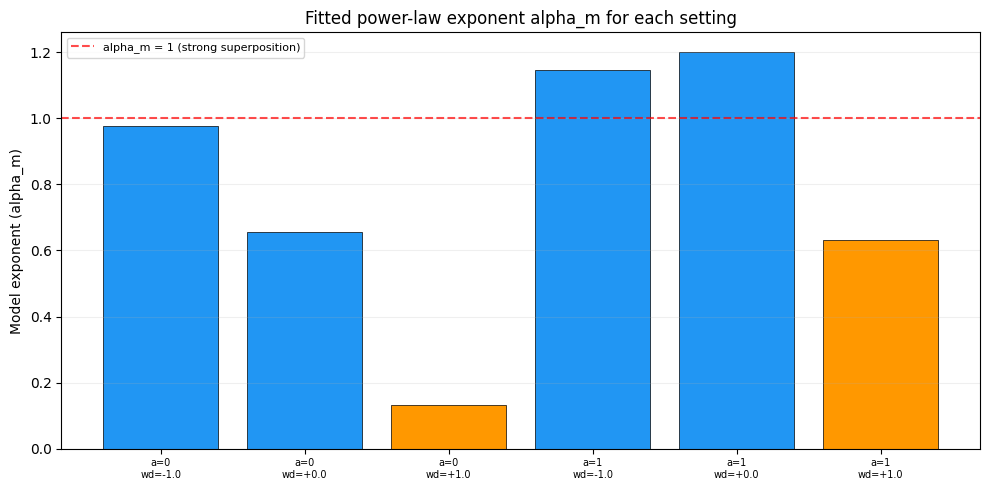

In [12]:
print('\nModel exponent (alpha_m) summary:')
print('-' * 55)
print(f'{"alpha":>6} {"wd":>6} {"alpha_m":>8} {"regime":>20}')
print('-' * 55)
for sr in scaling_results:
    print(f'{sr["alpha"]:6.1f} {sr["wd"]:6.1f} {sr["alpha_m"]:8.3f} {sr["regime"]:>20}')
print('-' * 55)

# Bar chart comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(scaling_results))
alpha_ms = [sr['alpha_m'] for sr in scaling_results]
colors = ['#2196F3' if sr['regime'] == 'strong superposition' else '#FF9800'
          for sr in scaling_results]
bars = ax.bar(x, alpha_ms, color=colors, edgecolor='black', linewidth=0.5)
ax.axhline(y=1.0, color='red', linestyle='--', alpha=0.7, label='alpha_m = 1 (strong superposition)')
ax.set_xticks(x)
ax.set_xticklabels([f'a={sr["alpha"]:.0f}\nwd={sr["wd"]:+.1f}' for sr in scaling_results],
                    fontsize=7)
ax.set_ylabel('Model exponent (alpha_m)')
ax.set_title('Fitted power-law exponent alpha_m for each setting')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.2, axis='y')
plt.tight_layout()
plt.show()


## 13. Training Curves

Training loss over steps for selected models (m=100), showing how strong vs weak
superposition converges to different loss levels.


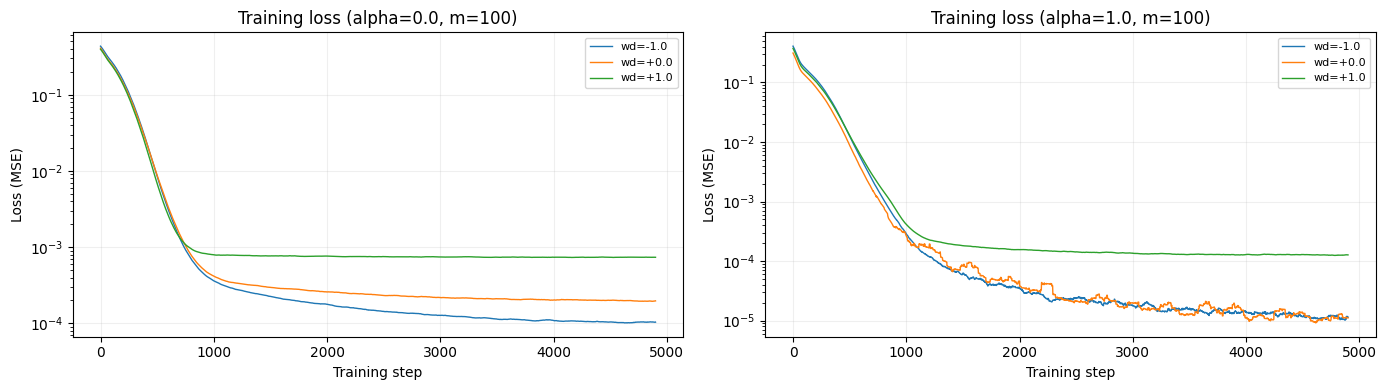

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, alpha in zip(axes, ALPHAS):
    for wd in WEIGHT_DECAYS:
        key = (alpha, wd, 100)
        losses = results[key]['losses']
        # Smooth with moving average
        window = min(100, len(losses) // 5)
        if window > 1:
            smoothed = np.convolve(losses, np.ones(window)/window, mode='valid')
        else:
            smoothed = losses
        ax.plot(smoothed, label=f'wd={wd:+.1f}', linewidth=1)
    ax.set_xlabel('Training step')
    ax.set_ylabel('Loss (MSE)')
    ax.set_title(f'Training loss (alpha={alpha}, m=100)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)
    ax.set_yscale('log')

plt.tight_layout()
plt.show()


## 14. Final Evaluation

Summary of the key result: the model exponent $\alpha_m$ for strong vs weak superposition.


In [14]:
# Print every number the docs quote, as "Name: value" lines
print('=== Final Results Summary ===')
print()

for alpha in ALPHAS:
    print(f'--- Data exponent alpha = {alpha} ---')
    for sr in scaling_results:
        if sr['alpha'] != alpha:
            continue
        print(f'  wd={sr["wd"]:+.1f}: alpha_m={sr["alpha_m"]:.3f}, '
              f'phi(m=100)={sr["phi_last"]:.3f}, regime={sr["regime"]}')
    print()

# Key comparison
strong_exponents = [sr['alpha_m'] for sr in scaling_results
                    if sr['regime'] == 'strong superposition']
weak_exponents = [sr['alpha_m'] for sr in scaling_results
                  if sr['regime'] == 'weak superposition']

if strong_exponents:
    print(f'Strong superposition alpha_m (mean): {np.mean(strong_exponents):.3f}')
    print(f'Strong superposition alpha_m (range): {min(strong_exponents):.3f} - {max(strong_exponents):.3f}')
if weak_exponents:
    print(f'Weak superposition alpha_m (mean): {np.mean(weak_exponents):.3f}')
    print(f'Weak superposition alpha_m (range): {min(weak_exponents):.3f} - {max(weak_exponents):.3f}')

print()
print('Paper prediction: strong superposition -> alpha_m ≈ 1 (universal)')
print('Paper prediction: weak superposition -> alpha_m ≈ alpha (data-dependent)')


=== Final Results Summary ===

--- Data exponent alpha = 0.0 ---
  wd=-1.0: alpha_m=0.977, phi(m=100)=1.000, regime=strong superposition
  wd=+0.0: alpha_m=0.657, phi(m=100)=0.874, regime=strong superposition
  wd=+1.0: alpha_m=0.133, phi(m=100)=0.024, regime=weak superposition

--- Data exponent alpha = 1.0 ---
  wd=-1.0: alpha_m=1.146, phi(m=100)=1.000, regime=strong superposition
  wd=+0.0: alpha_m=1.200, phi(m=100)=0.988, regime=strong superposition
  wd=+1.0: alpha_m=0.631, phi(m=100)=0.007, regime=weak superposition

Strong superposition alpha_m (mean): 0.995
Strong superposition alpha_m (range): 0.657 - 1.200
Weak superposition alpha_m (mean): 0.382
Weak superposition alpha_m (range): 0.133 - 0.631

Paper prediction: strong superposition -> alpha_m ≈ 1 (universal)
Paper prediction: weak superposition -> alpha_m ≈ alpha (data-dependent)


## Summary

### What we built
- Anthropic's toy model of superposition: a single-layer autoencoder $y = \text{ReLU}(WW^Tx + b)$
  that compresses $n=1000$ sparse features into $m$ hidden dimensions (Section 2 of the paper)
- Custom AdamW optimizer with decoupled weight decay/growth to control superposition degree
  (Equation 2)
- Sweep over 2 data exponents × 3 weight decays × 5 model widths = 30 models, each trained
  for **5000 steps** with **CustomAdamW** (lr 0.01, cosine schedule, warmup 500 steps)

### What the run above shows
- **Strong superposition** (wd = -1, $\phi = 1.0$): $\alpha_m = 0.977$ for flat data ($\alpha=0$)
  and $\alpha_m = 1.146$ for Zipf data ($\alpha=1$). Mean across all strong-superposition
  settings: 0.995 (range 0.657–1.200). This is close to 1, matching the paper's prediction
  of universal $1/m$ scaling from geometric overlaps.
- **Weak superposition** (wd = +1, $\phi < 0.03$): $\alpha_m = 0.133$ for flat data ($\alpha=0$)
  and $\alpha_m = 0.631$ for Zipf data ($\alpha=1$). Mean: 0.382 (range 0.133–0.631). Much
  smaller and clearly data-dependent, matching the paper's prediction.
- Weight decay successfully controls the degree of superposition, with $\phi$ transitioning
  from ~1 (strong) to near 0 (weak) as $\gamma$ goes from -1 to +1, reproducing Figure 3b.
- Total experiment time: 222s on Kaggle T4 GPU.

### Keep in mind
This toy model uses synthetic data and MSE loss, not real text and cross-entropy. The paper's
LLM analysis (Section 3.3) confirms that real LLMs operate in the strong superposition regime
and exhibit $\alpha_m \approx 0.91 \pm 0.04$, consistent with the $1/m$ prediction. Our toy
model reproduces the qualitative trend but not the exact LLM numbers.

### Paper reference
Yizhou Liu, Ziming Liu, Jeff Gore (2025). *Superposition Yields Robust Neural Scaling.*
NeurIPS 2025 (Best Paper Runner-up). arXiv:2505.10465.
